# Lab 5-02：function calling 迴圈——模型＋迴圈＝agent

**目標**：把 01 的 ReAct 換成 function calling。模型不再寫 `Action: …` 文字，而是回一個結構化的 `tool_calls`；
我們寫一個 while 迴圈去執行它，直到模型說完為止。

**你會學到**
- 工具說明書（JSON Schema）怎麼從 Pydantic 自動產生
- 一輪 tool calling 的完整 messages：`assistant(tool_calls)` → `tool` → `assistant`
- 50 行左右的 agent 迴圈：`max_steps` 保險絲、參數驗證、錯誤回饋
- 每一輪的 token 怎麼長大

**前置**：Lab 5-01。`qwen2.5:3b` 經 Ollama 的 OpenAI 相容端點支援 tools。

**對應投影片**：「一段真實的 tool calling」「50 行手寫 agent」「Workflow 還是 Agent」

![messages 隨迴圈增長的概念圖](images/messages_stack.jpg)

*圖：每一輪送給模型的都是整串 messages。第 2 輪多了模型的 tool_calls 和工具結果，第 3 輪再多一則回答。agent 的「記憶」就是這一疊卡片，越疊越高，也越來越貴。*

## Step 1：工具的說明書從 Pydantic 來

function calling 要先告訴模型「有哪些工具、參數長什麼樣」，格式是 JSON Schema。
手寫 JSON Schema 很容易錯，這裡用 Pydantic 定義參數，再讓它自動產生。好處是**同一份定義**之後還能拿來驗證模型給的參數。

參數模型寫在 `oncall_tools.py`，先看其中一個。

In [1]:
import json

import oncall_tools as ot

print(ot.ReadLogsArgs.model_json_schema()["properties"]["service"])

{'anyOf': [{'enum': ['web-gateway', 'order-api', 'order-db-proxy', 'payment-api', 'notification'], 'type': 'string'}, {'type': 'null'}], 'default': None, 'description': '只看這個服務；不填就看全部', 'title': 'Service'}


In [2]:
from pydantic import BaseModel, Field


class CalculatorArgs(BaseModel):
    expression: str = Field(..., description="四則運算算式，例如 27.1 / 0.3")


# 工具註冊表：名稱 → (函式, 參數模型, 說明)
REGISTRY = {
    "read_logs": (ot.read_logs, ot.ReadLogsArgs, "讀應用程式日誌，可依服務、等級、關鍵字過濾"),
    "query_metrics": (ot.query_metrics, ot.QueryMetricsArgs, "查某個服務的監控指標，回傳最近幾個時間點"),
    "calculator": (ot.calculator, CalculatorArgs, "計算四則運算"),
}


def to_openai_tool(name: str) -> dict:
    _, args_model, desc = REGISTRY[name]
    return {"type": "function",
            "function": {"name": name, "description": desc, "parameters": args_model.model_json_schema()}}


TOOLS = [to_openai_tool(n) for n in REGISTRY]
print(json.dumps(TOOLS[2], ensure_ascii=False, indent=1))

{
 "type": "function",
 "function": {
  "name": "calculator",
  "description": "計算四則運算",
  "parameters": {
   "properties": {
    "expression": {
     "description": "四則運算算式，例如 27.1 / 0.3",
     "title": "Expression",
     "type": "string"
    }
   },
   "required": [
    "expression"
   ],
   "title": "CalculatorArgs",
   "type": "object"
  }
 }
}


## Step 2：送出一次，看模型回什麼

這次直接用 `openai` SDK（`course_utils.chat` 只回文字，看不到 `tool_calls`）。
注意回覆的 `content` 是空的，取而代之的是 `tool_calls`：工具名稱＋JSON 字串格式的參數。

In [3]:
import os

from openai import OpenAI

client = OpenAI(base_url=os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1"), api_key="ollama")
MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")
SYSTEM = "你是晨光外送的值班助理。先用工具查證，再用繁體中文回答，回答要附上數字。"

question = "下單一直 502。請查 order-api 的 ERROR 日誌，再查 order-api 目前的 error_rate，最後算出它是平常 0.3% 的幾倍。"
messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]

resp = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, temperature=0)
msg = resp.choices[0].message
print("content   :", repr(msg.content))
for call in msg.tool_calls or []:
    print("tool_call :", call.function.name, call.function.arguments)
print("usage     :", resp.usage.prompt_tokens, "prompt tokens,", resp.usage.completion_tokens, "completion tokens")

content   : ''
tool_call : read_logs {"level":"ERROR","limit":10,"service":"order-api","keyword":"502"}
tool_call : query_metrics {"service":"order-api","metric":"error_rate"}
usage     : 511 prompt tokens, 70 completion tokens


跟 01 比一比：以前我們用正規表示式從一段文字裡挖出 `Action: read_logs: order-api ERROR`；
現在 API 直接給我們工具名稱和 JSON 參數。解析這一段交給模型廠商訓練好了，格式錯誤少很多。

## Step 3：手動走完一輪

模型只是「提出」要呼叫工具，**真的去執行的是我們**。執行完，用 `role: "tool"` 加上同一個 `tool_call_id` 把結果送回去。

In [4]:
messages.append(msg.model_dump(exclude_none=True))  # 模型這一輪的回覆（含 tool_calls）也要存進去
for call in msg.tool_calls:
    fn, args_model, _ = REGISTRY[call.function.name]
    args = args_model.model_validate_json(call.function.arguments)  # 用同一個 Pydantic 模型驗證
    result = fn(**args.model_dump())
    messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
    print(f"執行 {call.function.name}({args.model_dump(exclude_none=True)})\n→ {result[:150]}")

執行 read_logs({'service': 'order-api', 'level': 'ERROR', 'keyword': '502', 'limit': 10})
→ （沒有符合的日誌）
執行 query_metrics({'service': 'order-api', 'metric': 'error_rate'})
→ order-api error_rate 最近：14:00=8.1, 14:05=24.5, 14:10=27.9, 14:15=28.3, 14:20=26.0, 14:25=27.1；目前 27.1


現在 messages 裡有四則：system、user、assistant（帶 tool_calls）、tool。再送一次，模型就讀得到工具結果。

In [5]:
for m in messages:
    body = m.get("content") or json.dumps([c["function"] for c in m.get("tool_calls", [])], ensure_ascii=False)
    print(f"[{m['role']:<9}] {body[:100]}")

resp = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, temperature=0)
msg = resp.choices[0].message
print("\n下一輪：", msg.content or [(c.function.name, c.function.arguments) for c in msg.tool_calls])

[system   ] 你是晨光外送的值班助理。先用工具查證，再用繁體中文回答，回答要附上數字。
[user     ] 下單一直 502。請查 order-api 的 ERROR 日誌，再查 order-api 目前的 error_rate，最後算出它是平常 0.3% 的幾倍。
[assistant] [{"arguments": "{\"level\":\"ERROR\",\"limit\":10,\"service\":\"order-api\",\"keyword\":\"502\"}", "
[tool     ] （沒有符合的日誌）
[tool     ] order-api error_rate 最近：14:00=8.1, 14:05=24.5, 14:10=27.9, 14:15=28.3, 14:20=26.0, 14:25=27.1；目前 27.

下一輪： 根據查詢結果，order-api 的 error_rate 最近的值為 27.1%，而平常的 error_rate 是 0.3%。

因此，order-api 的 error_rate 是平常的倍數為：27.1 / 0.3 = 90.33倍。


## Step 4：把「一輪」包成迴圈

剛才的手動步驟重複做，直到模型不再要工具為止。這就是 agent：

```
while 還沒超過 max_steps:
    回覆 = 模型(messages, 工具清單)
    沒有 tool_calls → 回傳答案，結束
    有 tool_calls   → 一個一個執行，結果追加進 messages
```

三個防護一起加上：參數驗證失敗、未知工具、工具本身出錯，都變成 tool 訊息回給模型，不讓程式當掉。

In [6]:
import time

from pydantic import ValidationError


def execute(call) -> str:
    name = call.function.name
    if name not in REGISTRY:
        return f"錯誤：沒有 {name} 這個工具"
    fn, args_model, _ = REGISTRY[name]
    try:
        args = args_model.model_validate_json(call.function.arguments)
    except ValidationError as exc:
        return f"參數錯誤，請修正後重試：{exc.errors()[0]['loc']} {exc.errors()[0]['msg']}"
    try:
        return fn(**args.model_dump())
    except Exception as exc:
        return f"工具執行失敗：{exc}"


def run_agent(question: str, max_steps: int = 6, verbose: bool = True) -> tuple[str | None, list[dict], list[dict]]:
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    stats = []
    for step in range(1, max_steps + 1):
        t0 = time.time()
        resp = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS, temperature=0)
        msg = resp.choices[0].message
        messages.append(msg.model_dump(exclude_none=True))
        calls = msg.tool_calls or []
        stats.append({"step": step, "prompt": resp.usage.prompt_tokens, "completion": resp.usage.completion_tokens,
                      "seconds": time.time() - t0, "tools": [c.function.name for c in calls]})
        if verbose:
            print(f"── 第 {step} 輪：prompt {resp.usage.prompt_tokens} tokens，{time.time() - t0:.1f}s")
        if not calls:  # 終止條件：模型不再要工具
            if verbose:
                print("assistant：", msg.content)
            return msg.content, messages, stats
        for call in calls:
            result = execute(call)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
            if verbose:
                print(f"  {call.function.name}({call.function.arguments}) → {result[:90]}")
    return None, messages, stats  # 保險絲燒斷


answer, history, stats = run_agent(question)

── 第 1 輪：prompt 511 tokens，2.2s
  read_logs({"keyword":"502","level":"ERROR","limit":10,"service":"order-api"}) → （沒有符合的日誌）
  query_metrics({"service":"order-api","metric":"error_rate"}) → order-api error_rate 最近：14:00=8.1, 14:05=24.5, 14:10=27.9, 14:15=28.3, 14:20=26.0, 14:25=2
── 第 2 輪：prompt 688 tokens，1.3s
assistant： 根據查詢結果，order-api 的 error_rate 最近的值為 27.1%，而平常的 error_rate 是 0.3%。

因此，order-api 的 error_rate 是平常的倍數為：27.1 / 0.3 = 90.33倍。


看一下模型做了什麼決定。qwen2.5:3b 常會：
- **一輪就同時要兩個工具**（平行 tool calls），省下一輪。
- **自作主張加參數**，例如替 `read_logs` 加上 `keyword="502"`，結果 order-api 的日誌裡沒有這個字，查到空的。
- **不用計算機、自己心算**倍數。這次算對了，但沒有任何保證。

這些都不是迴圈寫錯，而是模型的決定。迴圈能做的是把每一步攤開給你看。

核心迴圈（`run_agent`）大約 20 行，加上工具註冊表與 `execute`，整份不到 50 行。投影片上那句「模型＋迴圈＝agent」就是這個意思。

## Step 5：印出完整的 messages

這一串就是 agent 的全部記憶。每一則的角色依序是：system → user → (assistant 要工具 → tool 結果) × N → assistant 回答。

In [7]:
for i, m in enumerate(history):
    if m.get("tool_calls"):
        body = "要求呼叫 " + ", ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m["tool_calls"])
    else:
        body = (m.get("content") or "").replace("\n", " ")
    print(f"{i:>2} [{m['role']:<9}] {body[:110]}")

 0 [system   ] 你是晨光外送的值班助理。先用工具查證，再用繁體中文回答，回答要附上數字。
 1 [user     ] 下單一直 502。請查 order-api 的 ERROR 日誌，再查 order-api 目前的 error_rate，最後算出它是平常 0.3% 的幾倍。
 2 [assistant] 要求呼叫 read_logs{"keyword":"502","level":"ERROR","limit":10,"service":"order-api"}, query_metrics{"service":"ord
 3 [tool     ] （沒有符合的日誌）
 4 [tool     ] order-api error_rate 最近：14:00=8.1, 14:05=24.5, 14:10=27.9, 14:15=28.3, 14:20=26.0, 14:25=27.1；目前 27.1
 5 [assistant] 根據查詢結果，order-api 的 error_rate 最近的值為 27.1%，而平常的 error_rate 是 0.3%。  因此，order-api 的 error_rate 是平常的倍數為：27.1 / 0.


## Step 6：畫出每一輪的 token

左邊是每一輪送進去的 prompt tokens，右邊是時間軸。每多一輪，prompt 就多了上一輪的工具結果，所以一路往上長。
這也是為什麼工具的回傳要**短**：工具多吐一千字，之後每一輪都要再付一次。

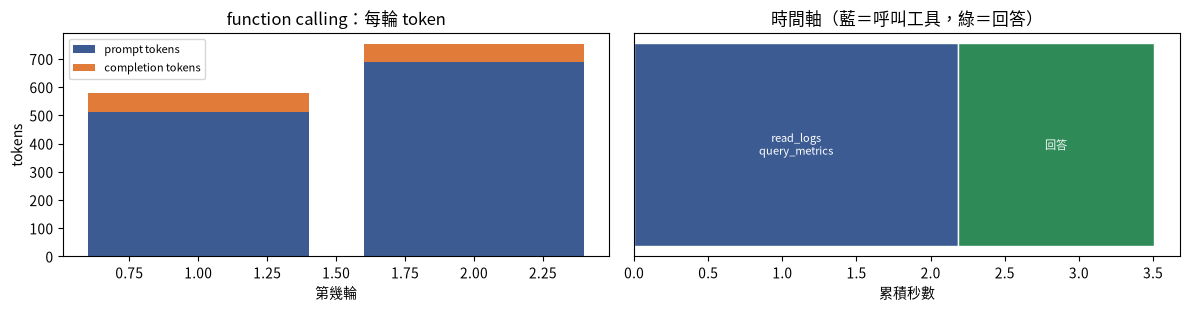

總 tokens： 1334


In [8]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()


def plot_stats(stats: list[dict], title: str) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.2))
    steps = [s["step"] for s in stats]
    ax1.bar(steps, [s["prompt"] for s in stats], label="prompt tokens", color="#3b5b92")
    ax1.bar(steps, [s["completion"] for s in stats], bottom=[s["prompt"] for s in stats],
            label="completion tokens", color="#e07b39")
    ax1.set_xlabel("第幾輪")
    ax1.set_ylabel("tokens")
    ax1.set_title(f"{title}：每輪 token")
    ax1.legend(fontsize=8)
    start = 0.0
    for s in stats:
        color = "#3b5b92" if s["tools"] else "#2e8b57"
        ax2.barh(0, s["seconds"], left=start, color=color, edgecolor="white")
        label = "\n".join(s["tools"]) or "回答"
        ax2.text(start + s["seconds"] / 2, 0, label, ha="center", va="center", color="white", fontsize=8)
        start += s["seconds"]
    ax2.set_yticks([])
    ax2.set_xlabel("累積秒數")
    ax2.set_title("時間軸（藍＝呼叫工具，綠＝回答）")
    plt.tight_layout()
    plt.show()


plot_stats(stats, "function calling")
print("總 tokens：", sum(s["prompt"] + s["completion"] for s in stats))

## Step 7：先看它壞掉——參數不合法

模型偶爾會給錯參數，例如服務名稱拼錯。我們假造一個工具呼叫，看 `execute` 怎麼處理：
Pydantic 擋下來，錯誤訊息當成 tool 結果送回去，模型下一輪通常會自己修正。

In [9]:
from types import SimpleNamespace

bad_call = SimpleNamespace(function=SimpleNamespace(name="query_metrics", arguments='{"service": "orders", "metric": "error_rate"}'))
print(execute(bad_call))

unknown_call = SimpleNamespace(function=SimpleNamespace(name="restart_service", arguments='{"service": "order-db-proxy"}'))
print(execute(unknown_call))

參數錯誤，請修正後重試：('service',) Input should be 'web-gateway', 'order-api', 'order-db-proxy', 'payment-api' or 'notification'
錯誤：沒有 restart_service 這個工具


第二個例子很重要：模型「想」重啟服務，但註冊表裡沒有這個工具，所以什麼都不會發生。
**agent 能做什麼，由你放進註冊表的工具決定**，不是由模型決定。寫入類的工具要怎麼安全地放進來，是 05 的主題。

## Step 8：保險絲燒斷

把 `max_steps` 設成 1：模型第一輪一定要工具，迴圈就結束了，拿到 `None`。

In [10]:
answer_short, _, stats_short = run_agent(question, max_steps=1, verbose=False)
print("答案：", answer_short, "；跑了", len(stats_short), "輪")

答案： None ；跑了 1 輪


## Step 9：Workflow 還是 Agent？

同樣的任務，其實也可以不讓模型決定，直接寫死三步（查日誌 → 查指標 → 算倍數），最後才請模型寫一句總結。
這就是 workflow：步驟固定、可預測、便宜。比一比兩者呼叫模型的次數。

In [11]:
from course_utils.llm import chat

t0 = time.time()
logs = ot.read_logs("order-api", "ERROR", limit=3)
rate = ot.query_metrics("order-api", "error_rate")
ratio = ot.calculator("27.1 / 0.3")
summary = chat([{"role": "user", "content": f"用兩句繁體中文總結：\n日誌：{logs}\n指標：{rate}\n是平常的 {ratio} 倍"}])
print(summary)
print(f"\nworkflow：呼叫模型 1 次，{time.time() - t0:.1f}s；agent：呼叫模型 {len(stats)} 次，{sum(s['seconds'] for s in stats):.1f}s")

日誌顯示，最近三次出現訂單API調用超時的情況，均發生在與資料庫代理之間。指標方面，最近14:10時，訂單API的錯誤率為27.9%，目前為27.1%，比平常的90.3333倍有所上升。

workflow：呼叫模型 1 次，2.3s；agent：呼叫模型 2 次，3.5s


步驟固定的工作寫成 workflow 就好；要「看了結果才知道下一步」的工作（例如不知道是哪個服務出問題）才需要 agent。
模組最後的架構也是這樣分：查原因交給 agent，重啟這種固定流程寫成圖。

## 試試看

1. 問一個需要先查日誌才知道要查哪個服務的問題，例如「502 的根因是哪個服務？查它的指標給我證據」，看模型是不是會根據日誌決定下一步。
2. 把 `read_logs` 的 `limit` 預設改成 30，再跑一次 Step 4，看 prompt tokens 長了多少。
3. 在 `REGISTRY` 的說明裡刪掉 `query_metrics` 的說明文字（改成空字串），看模型還會不會用它。

## 小結

- function calling 讓模型回結構化的 `tool_calls`；工具還是你執行，結果用 `role: tool` 送回去。
- 一個能用的 agent 迴圈：工具註冊表＋Pydantic 驗證＋錯誤回饋＋`max_steps`，核心不到 20 行。
- 下一本 03 把模組 3 的檢索包成一個工具，讓 agent 自己決定什麼時候該去查 runbook。